# Credit Profile Analysis
## Paisabazaar case study — synthetic demonstration

A completed portfolio extension of VenkyAdi's banking EDA. The upstream CSV is missing, so this notebook uses a newly generated, explicitly synthetic customer panel. All results describe that demonstration, not actual Paisabazaar customers.

**Questions:** What quality problems exist? How do credit profiles differ by score? Can simple models distinguish the designed classes for held-out customers?

The source target is credit score, not fraud. This notebook makes no fraud-detection or lending-performance claim. See `PROVENANCE.md` for attribution.

## 1. Reproducible setup

Run all cells from the repository root or the notebooks folder after installing the project. The notebook uses the same tested modules as the command-line pipeline; it does not maintain a second implementation.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'credit_analysis').exists():
    ROOT = ROOT.parent
assert (ROOT / 'credit_analysis').exists(), 'Open this notebook inside the repository'
sys.path.insert(0, str(ROOT))

from credit_analysis.data import clean_data, FEATURES, LABELS
from credit_analysis.pipeline import run_analysis
INPUT = ROOT / 'data/demo/synthetic_credit.csv'
OUTPUT = ROOT / 'reports/local/notebook'
SEED = 42
print('Data status: SYNTHETIC DEMONSTRATION')

Data status: SYNTHETIC DEMONSTRATION


## 2. Dataset and provenance

Each row represents a customer in one month. Stable customer characteristics repeat over eight months; financial stress, payment variability and noisy labels create imperfect relationships. Missing values, invalid ages, placeholder categories and exact duplicates are deliberately injected. No names or SSNs are generated.

In [2]:
manifest = json.loads(INPUT.with_suffix('.metadata.json').read_text(encoding='utf-8'))
assert manifest['synthetic'] is True
raw = pd.read_csv(INPUT, low_memory=False)
display(pd.Series({
    'Input rows': len(raw), 'Input columns': len(raw.columns),
    'Unique customers': raw.Customer_ID.nunique(), 'Months': raw.Month.nunique(),
    'Exact duplicates': int(raw.duplicated().sum()), 'Generation seed': manifest['seed']
}, name='Synthetic dataset overview').to_frame())

,Synthetic dataset overview
Input rows,12024
Input columns,26
Unique customers,1500
Months,8
Exact duplicates,24
Generation seed,42


## 3. Cleaning and quality audit

Cleaning removes exact duplicates, parses numeric suffixes and credit-history text, and replaces invalid domains with missing values. It retains valid monetary extremes and does not globally impute. The derived debt/annual-income ratio is a stock-to-income ratio; EMI/net monthly salary measures only installment burden.

In [3]:
cleaned, quality = clean_data(raw)
display(pd.DataFrame(quality['columns']).T.fillna(0).astype(int))
assert quality['clean_rows'] == len(cleaned)
assert not cleaned.duplicated(['Customer_ID', 'Month']).any()
print(f"Cleaned observations: {len(cleaned):,}; customers: {quality['customers']:,}")

,missing_before,parse_failures,domain_invalid,missing_after
Age,0,0,60,60
Annual_Income,0,0,0,0
Monthly_Inhand_Salary,240,0,0,240
Num_Bank_Accounts,0,0,0,0
Num_Credit_Card,0,0,0,0
Interest_Rate,0,0,0,0
Num_of_Loan,0,0,0,0
Delay_from_due_date,0,0,0,0
Num_of_Delayed_Payment,0,0,0,0
Changed_Credit_Limit,0,0,0,0


Cleaned observations: 12,000; customers: 1,500


## 4. Execute the full analysis

The pipeline verifies the CSV checksum, generates six figures and aggregate tables, compares three models on customer-separated partitions, and writes a reproducibility manifest. Synthetic status is attached to the report and every chart.

In [4]:
results = run_analysis(INPUT, OUTPUT, seed=SEED)
metrics = results['metrics']
assert results['run']['data_kind'] == 'synthetic'
display(pd.Series(results['run']['packages'], name='Runtime version').to_frame())

Completed SYNTHETIC analysis: C:\Users\gaur5\OneDrive\Attachments\EDA_Projects\reports\local\notebook\REPORT.md


,Runtime version
numpy,2.2.6
pandas,3.0.3
matplotlib,3.10.8
scikit-learn,1.9.0


## 5. Univariate exploration

Class percentages use labeled customer-month observations as the denominator. The income distribution is deliberately right-skewed. Repeated monthly rows are not independent customers.

,Score,Observations,Share of labeled rows (%)
0,Poor,4127,34.391667
1,Standard,5600,46.666667
2,Good,2273,18.941667


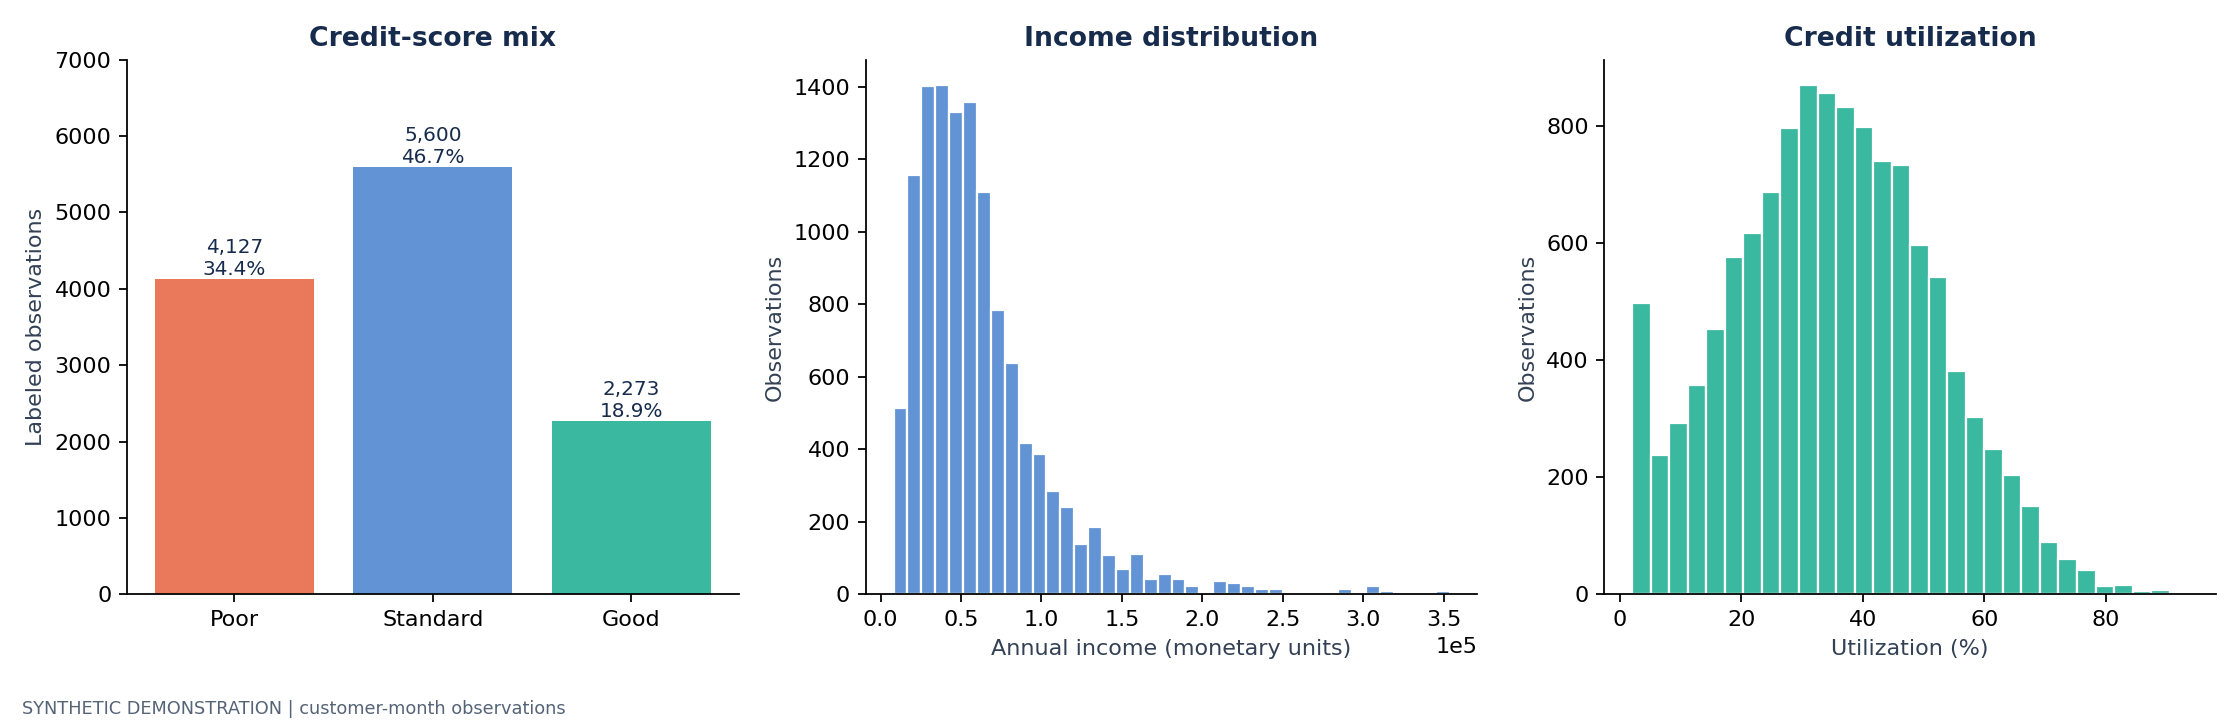

In [5]:
distribution = pd.read_csv(OUTPUT / 'score_distribution.csv')
display(distribution)
display(Image(filename=str(OUTPUT / 'figures/overview.png')))

## 6. Missingness and financial profiles

EDA summaries use available values, with no imputation. Boxplots suppress outlier markers for readability, while all observations remain in the calculations.

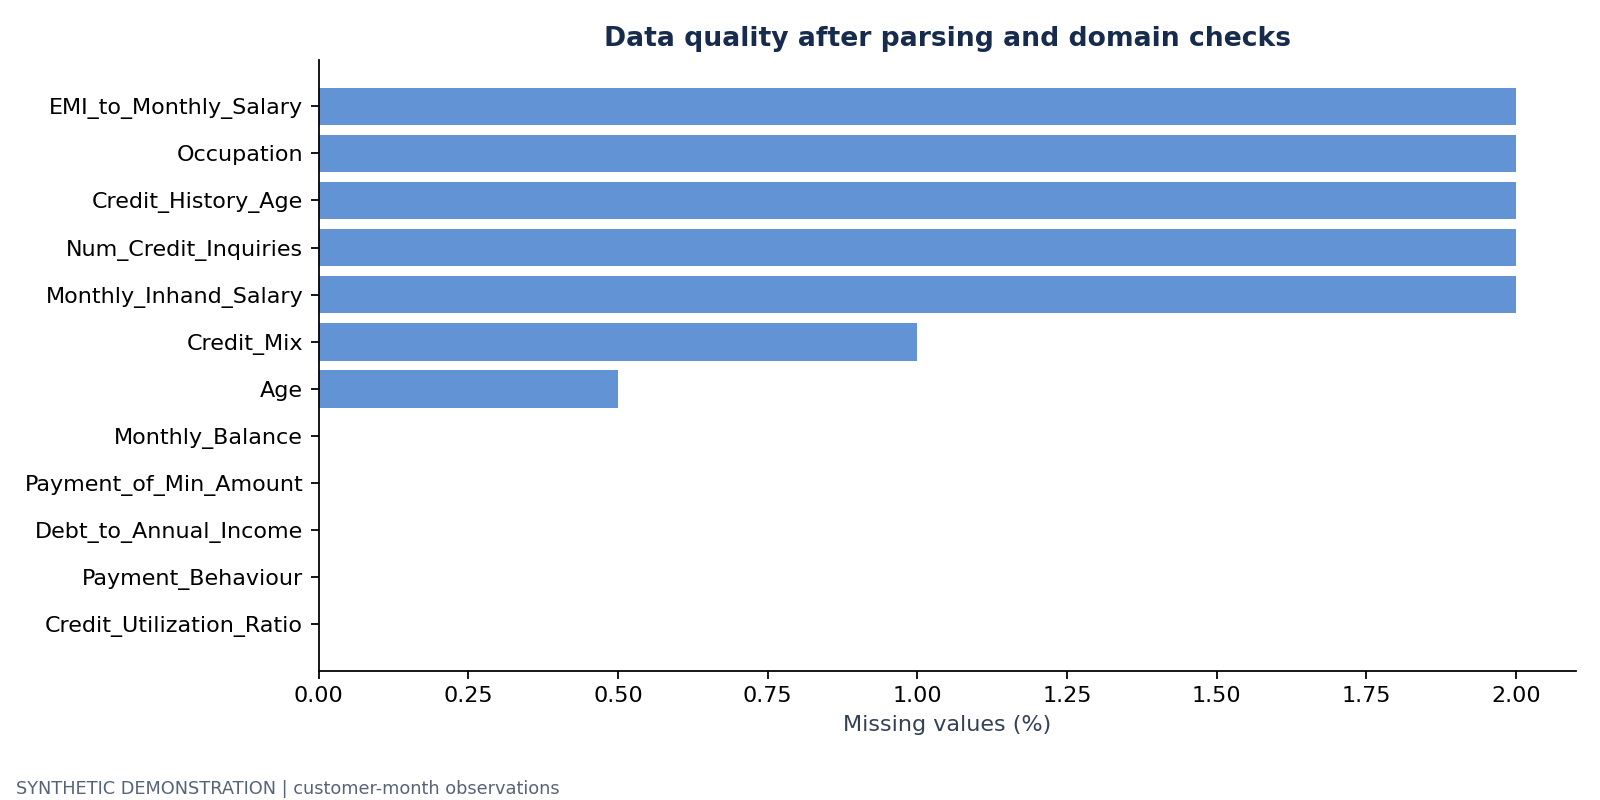

,Credit_Score,Annual_Income,Outstanding_Debt,Delay_from_due_date,Credit_Utilization_Ratio,EMI_to_Monthly_Salary
0,Poor,52671.490,17006.40,18.0,47.77,0.190244
1,Standard,52613.455,8048.87,9.0,32.28,0.110068
2,Good,49545.380,1277.37,1.0,17.05,0.035420


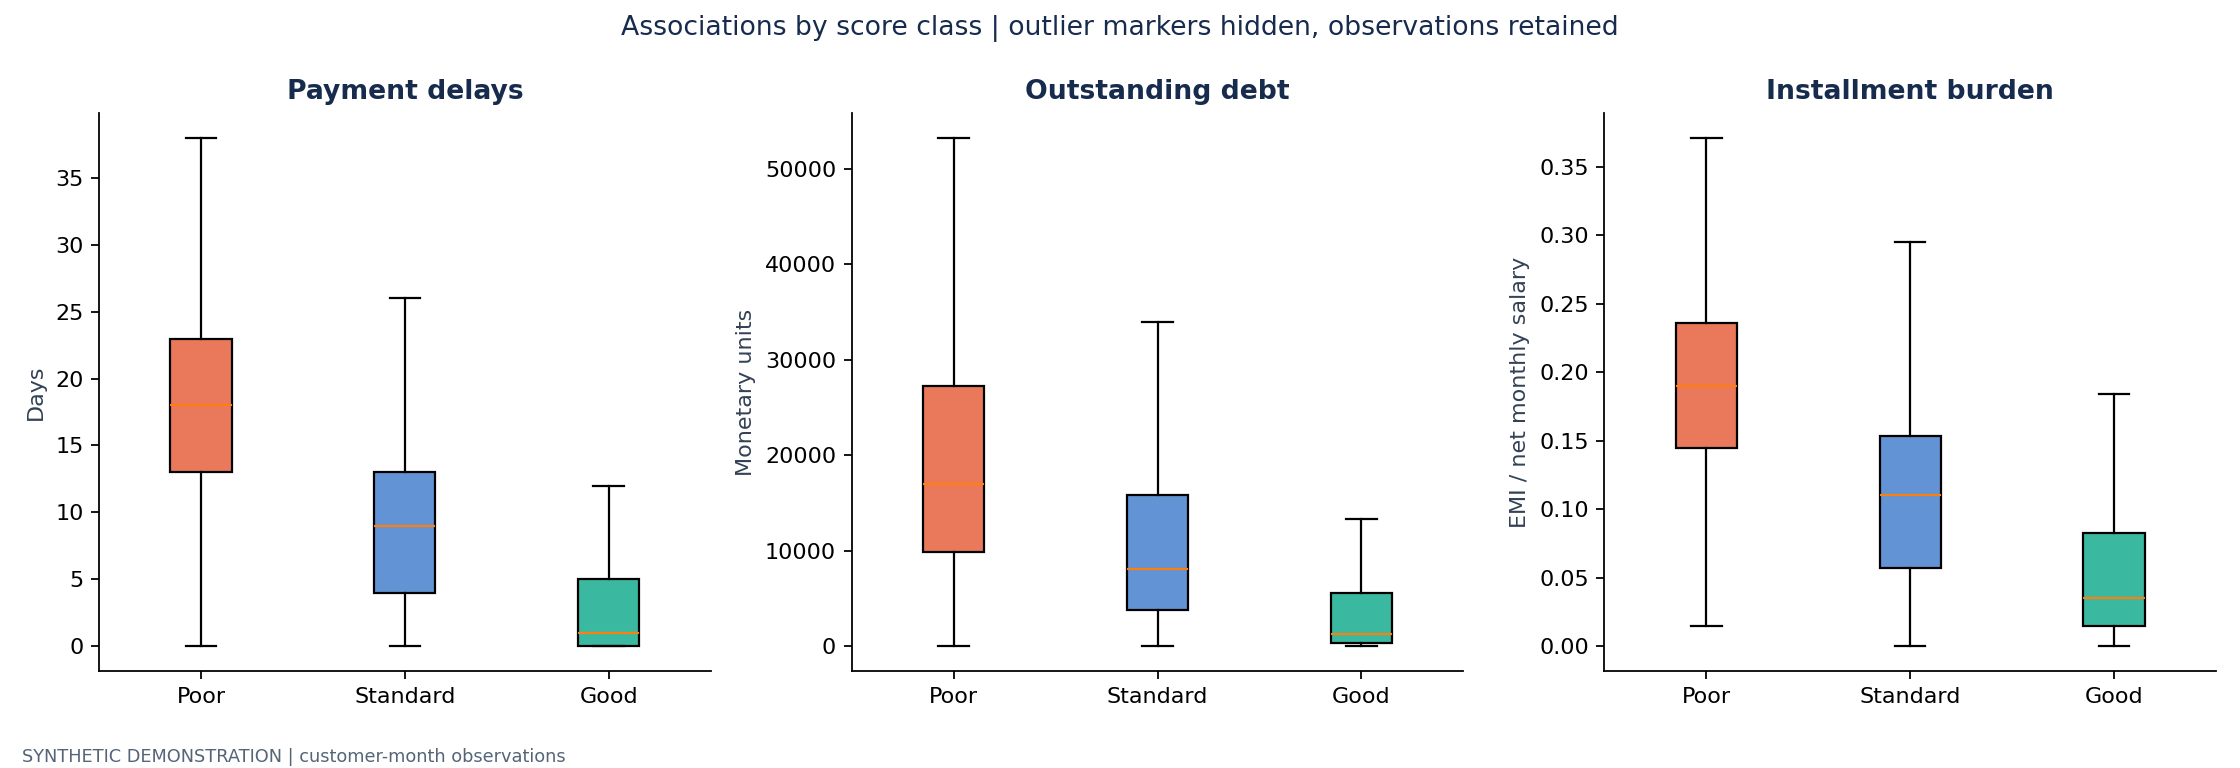

In [6]:
display(Image(filename=str(OUTPUT / 'figures/data_quality.png')))
profiles = pd.read_csv(OUTPUT / 'median_credit_profiles.csv')
display(profiles)
display(Image(filename=str(OUTPUT / 'figures/credit_profiles.png')))

## 7. Multivariate and monthly exploration

Spearman correlations measure monotonic associations using pairwise complete observations. They are not causal effects. Monthly class mix is descriptive and cannot establish future performance.

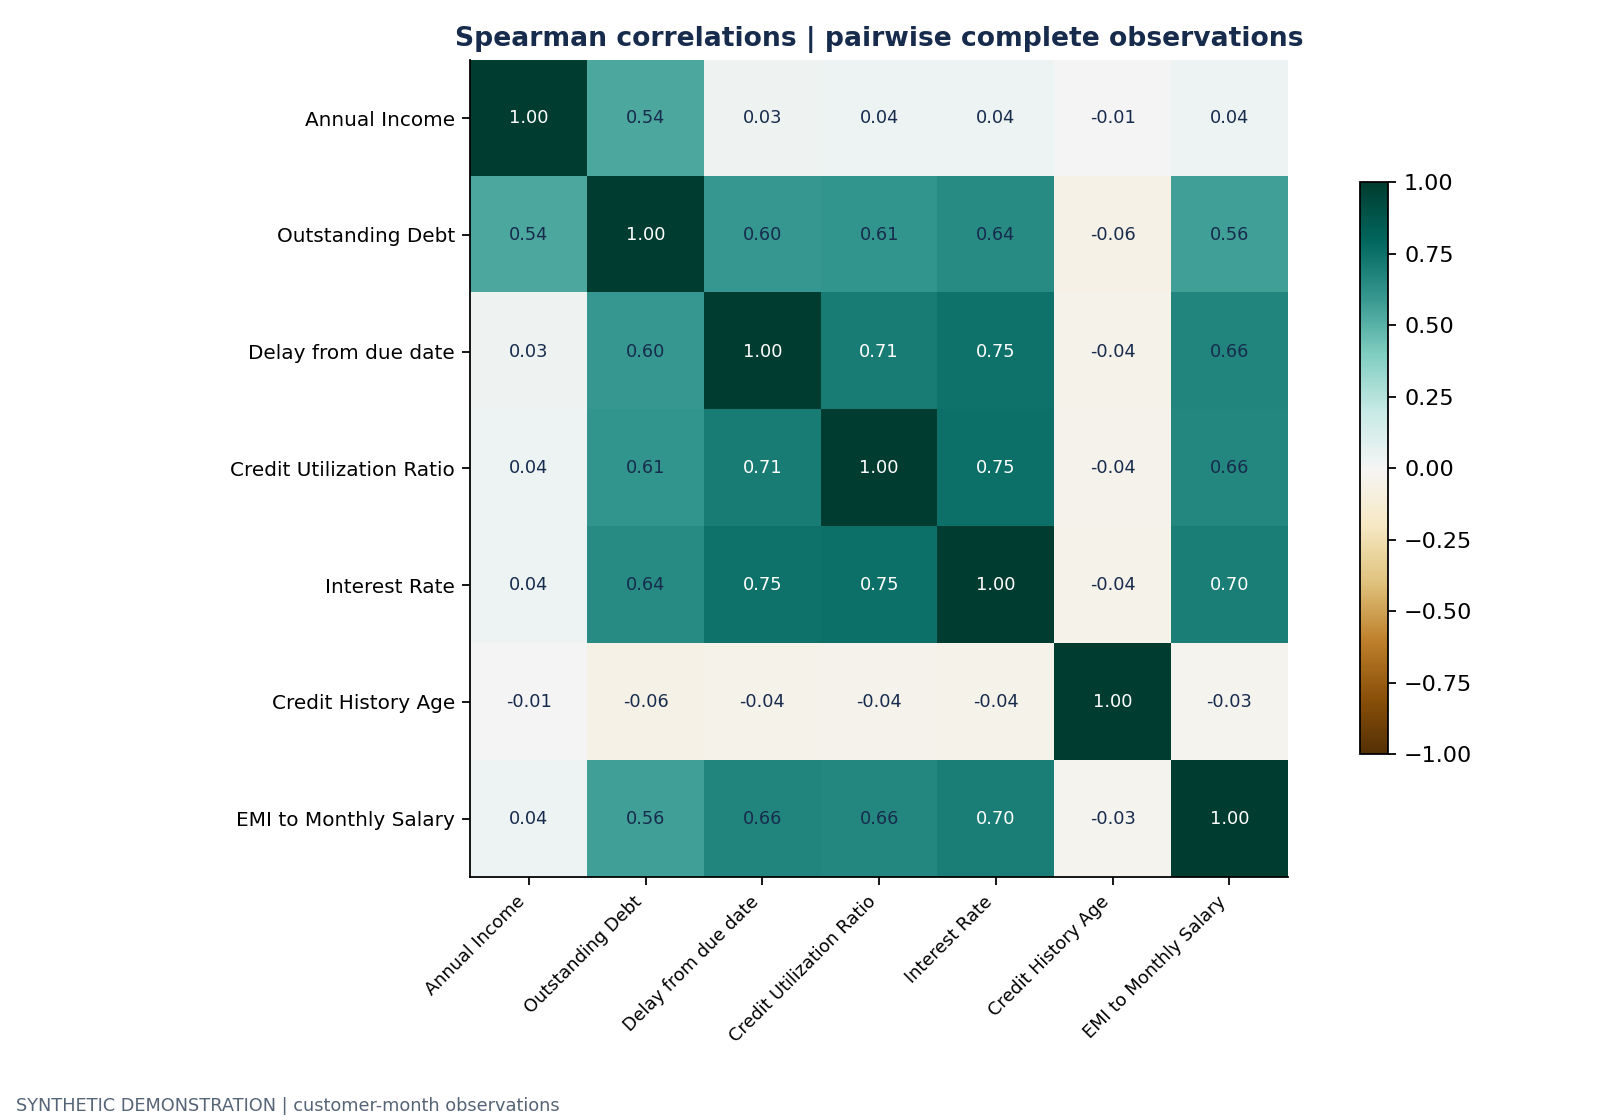

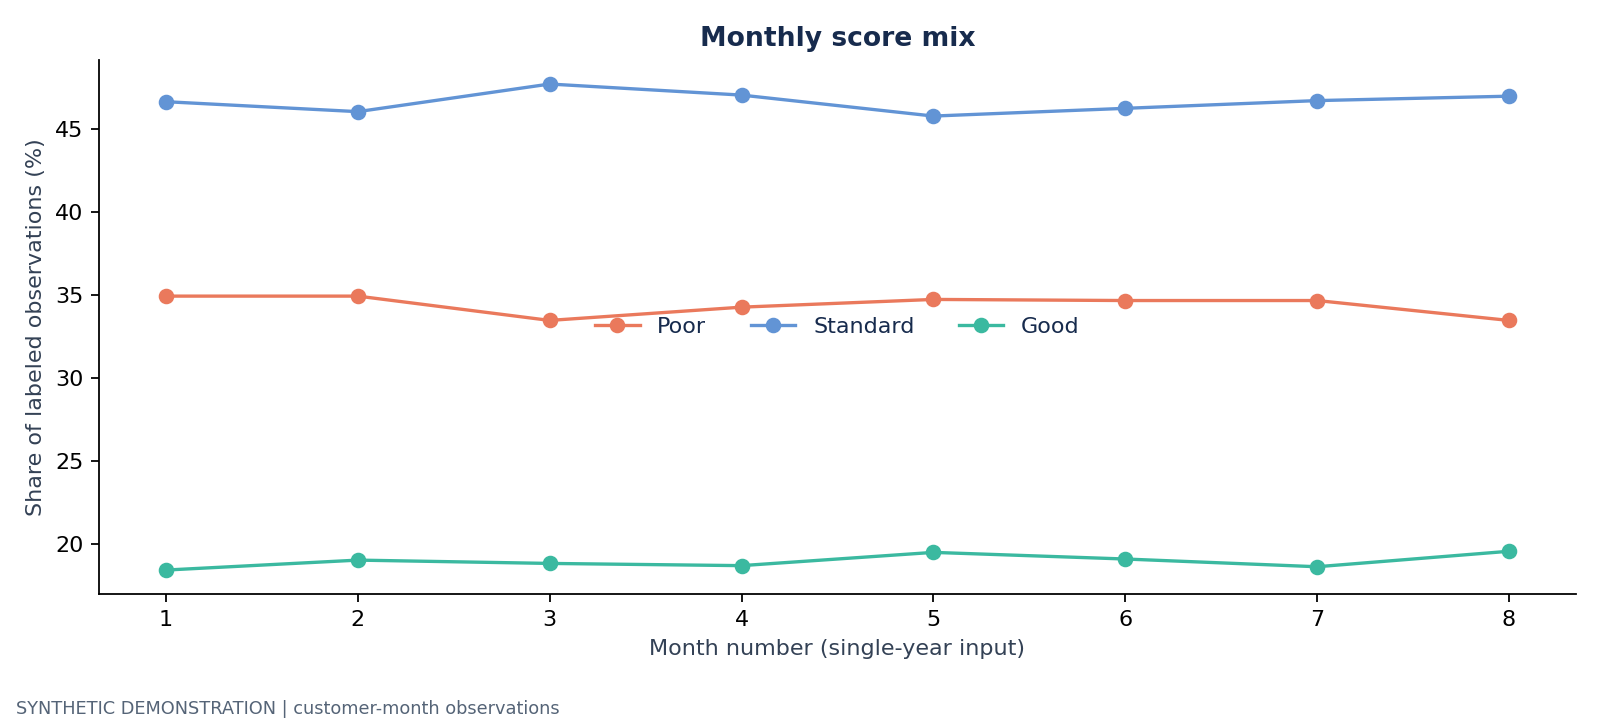

In [7]:
display(Image(filename=str(OUTPUT / 'figures/correlations.png')))
display(Image(filename=str(OUTPUT / 'figures/monthly_mix.png')))

## 8. Evaluation design and model selection

Split customers 60/20/20 into train, validation and test; all months for each customer stay together. Median imputation, scaling and one-hot encoding are learned within training pipelines. Validation macro F1 selects among a majority baseline, logistic regression and random forest. The winner is refitted on training plus validation before the final holdout evaluation.

IDs, names, SSNs, month, free-text loan descriptions and Credit_Score are excluded from predictors. Customer separation does not resolve contemporaneous label timing; this is a same-period new-customer experiment.

In [8]:
split = pd.DataFrame({name: {key: value for key, value in info.items() if key != 'class_counts'}
                      for name, info in metrics['split'].items()}).T
display(split)
display(pd.DataFrame(metrics['validation']).T)
assert metrics['customer_overlap'] == 0
print('Selected model:', metrics['selected_model'])

,rows,customers
train,7200,900
validation,2400,300
test,2400,300


,accuracy,balanced_accuracy,macro_f1
majority_baseline,0.462500,0.333333,0.210826
logistic_regression,0.684167,0.710067,0.683519
random_forest,0.697917,0.692808,0.692709


Selected model: random_forest


## 9. Held-out results and uncertainty

Macro F1 weights each class equally, and balanced accuracy averages class recall. The interval resamples whole customers 200 times while keeping the fitted model fixed; it does not include retraining uncertainty or uncertainty about transfer to real customers.

,Selected model,Majority baseline
accuracy,0.688333,0.444583
balanced_accuracy,0.703772,0.333333
macro_f1,0.687042,0.205173


**Synthetic holdout macro F1:** 0.687; customer-bootstrap 95% interval **0.664–0.710**.

,precision,recall,f1-score,support
Poor,0.753846,0.801402,0.776897,856.0
Standard,0.678768,0.578257,0.624494,1067.0
Good,0.600688,0.731656,0.659735,477.0


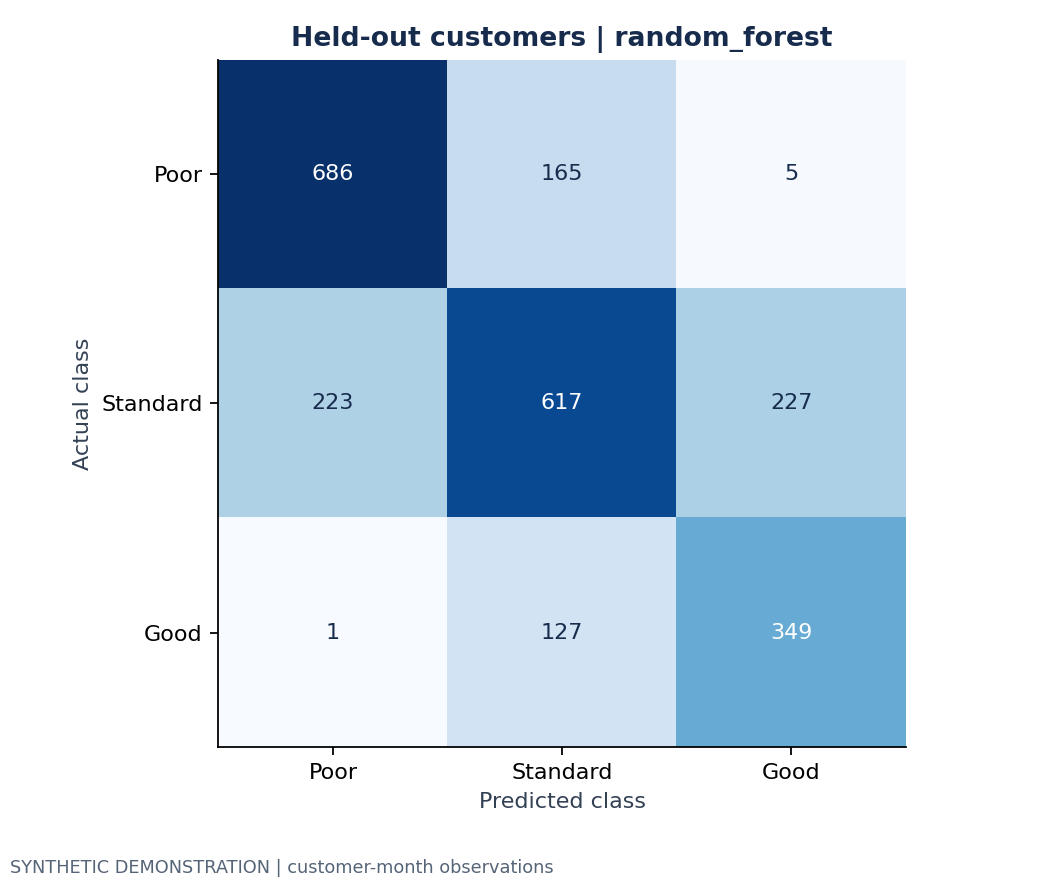

In [9]:
display(pd.DataFrame({'Selected model': metrics['test'], 'Majority baseline': metrics['test_majority_baseline']}))
low, high = metrics['test_macro_f1_customer_bootstrap_95pct']
display(Markdown(f"**Synthetic holdout macro F1:** {metrics['test']['macro_f1']:.3f}; customer-bootstrap 95% interval **{low:.3f}–{high:.3f}**."))
display(pd.DataFrame({label: metrics['classification_report'][label] for label in LABELS}).T)
display(Image(filename=str(OUTPUT / 'figures/confusion_matrix.png')))

## 10. Conclusions

The project demonstrates a reproducible workflow with clear source provenance, observable cleaning decisions, graphical EDA and an isolated customer holdout. Associations and model performance reflect designed synthetic relationships; they cannot validate credit policy, fraud detection or loan-default reduction.

With authorized real data, the next steps are to validate feature and target timing, confirm currency and units, evaluate future-period generalization, examine calibration and subgroup performance, and monitor data drift. The complete aggregate report is saved under `reports/local/notebook/REPORT.md`.

In [10]:
assert sum(map(sum, metrics['confusion_matrix'])) == metrics['split']['test']['rows']
assert set(FEATURES).isdisjoint({'ID', 'Customer_ID', 'Name', 'SSN', 'Credit_Score', 'Month'})
print('Checks passed: customer separation, excluded identifiers, and holdout counts.')

Checks passed: customer separation, excluded identifiers, and holdout counts.
